# Clustering Methods Exercises

![Clustering.png](Assets/Clustering.png)

# Цели обучения

- Обсудить алгоритмы обучения без учителя и способы их применения
- Применять кластеризацию
- Применять снижение размерности


## Введение

Для этих упражнений мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические характеристики вина, такие как кислотность, содержание сахара, pH и содержание алкоголя. Он также содержит показатель качества (от 3 до 9, где более высокое значение означает лучшее качество) и цвет (красное или белое). Имя файла — `Wine_Quality_Data`.

Мы будем использовать химические свойства (то есть все, кроме показателя качества и цвета) для кластеризации вин. Хотя это обучение без учителя, может быть интересно посмотреть, как результаты нашей кластеризации соотносятся с цветом и качеством.

In [1]:
from __future__ import print_function
import os
data_path = [  'data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import StratifiedShuffleSplit

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

## Вопрос 1

* Импортируйте данные и проанализируйте характеристики.
* Определите, какие из них являются непрерывными, категориальными и булевыми.
* Сколько записей имеется для двух цветов вина и диапазона показателей качества?
* Постройте гистограмму показателя качества для каждого из цветов вина.

In [2]:
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath)
print(data.shape)
data.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
print('Пропуски:', data.isna().sum().sum())
print('Полные дубликаты строк:', data.duplicated().sum())
data.describe().T

Пропуски: 0
Полные дубликаты строк: 1177


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile_acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric_acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual_sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free_sulfur_dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total_sulfur_dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


Типы данных для каждой записи. Реализация алгоритма K-means в библиотеке Scikit-learn рассчитана исключительно на работу с непрерывными данными (хотя иногда её применяют и для категориальных или булевых типов). К счастью, все столбцы, которые мы будем использовать (все, кроме «quality» и «color»), являются непрерывными.

In [4]:
data.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object

In [5]:
data.nunique().sort_values()

color                     2
quality                   7
citric_acid              89
fixed_acidity           106
pH                      108
sulphates               111
alcohol                 111
free_sulfur_dioxide     135
volatile_acidity        187
chlorides               214
total_sulfur_dioxide    276
residual_sugar          316
density                 998
dtype: int64

**Типы признаков:**

* Непрерывные: 11 химических характеристик (`fixed_acidity`, `volatile_acidity`, `citric_acid`, `residual_sugar`, `chlorides`, `free_sulfur_dioxide`, `total_sulfur_dioxide`, `density`, `pH`, `sulphates`, `alcohol`), все типа `float64`.
* Категориальный: `quality`, целые значения от 3 до 9 (7 уникальных значений), это порядковая оценка.
* Булев: `color`, принимает только два значения - `red` и `white`.

Пропусков в данных нет, полностью совпадающих строк 1177.

In [6]:
data['color'].value_counts()

color
white    4898
red      1599
Name: count, dtype: int64

In [7]:
pd.crosstab(data['quality'], data['color'], margins=True)

color,red,white,All
quality,,,
3,10,20,30
4,53,163,216
5,681,1457,2138
6,638,2198,2836
7,199,880,1079
8,18,175,193
9,0,5,5
All,1599,4898,6497


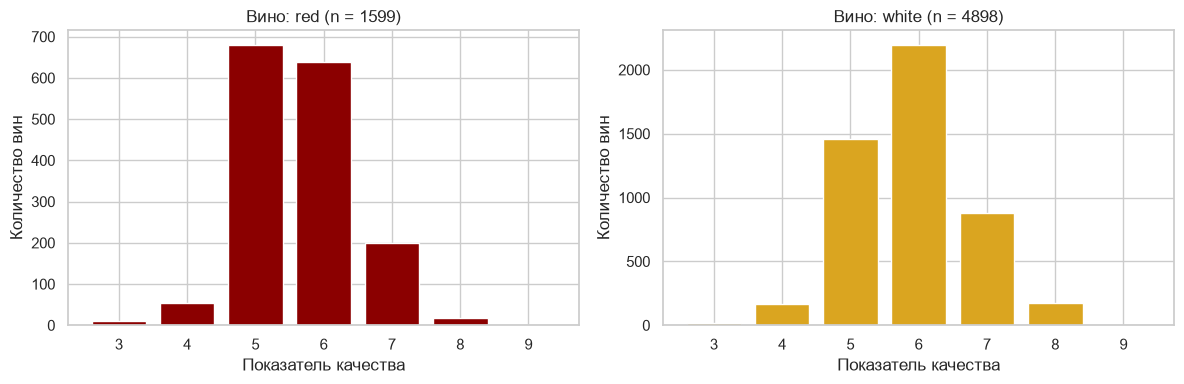

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, (color, group) in zip(axes, data.groupby('color')):
    counts = group['quality'].value_counts().reindex(range(3, 10), fill_value=0)
    ax.bar(counts.index, counts.values, color='darkred' if color == 'red' else 'goldenrod')
    ax.set(title=f'Вино: {color} (n = {len(group)})', xlabel='Показатель качества', ylabel='Количество вин')
plt.tight_layout()
plt.show()

**Вывод.** Белых вин 4898, красных 1599, то есть белых примерно в 3 раза больше. Качество принимает значения от 3 до 9, у красных вин максимальная оценка 8, а оценку 9 получили только 5 белых вин. У обоих цветов большинство вин имеют оценку 5 или 6, очень низкие и очень высокие оценки встречаются редко.

## Вопрос 2

* Оцените корреляцию и асимметрию соответствующих переменных — всех, кроме цвета и качества.
* Проведите необходимые преобразования признаков и/или масштабирование.
* Проанализируйте парное распределение переменных с помощью парных графиков, чтобы проверить правильность масштабирования и нормализации.


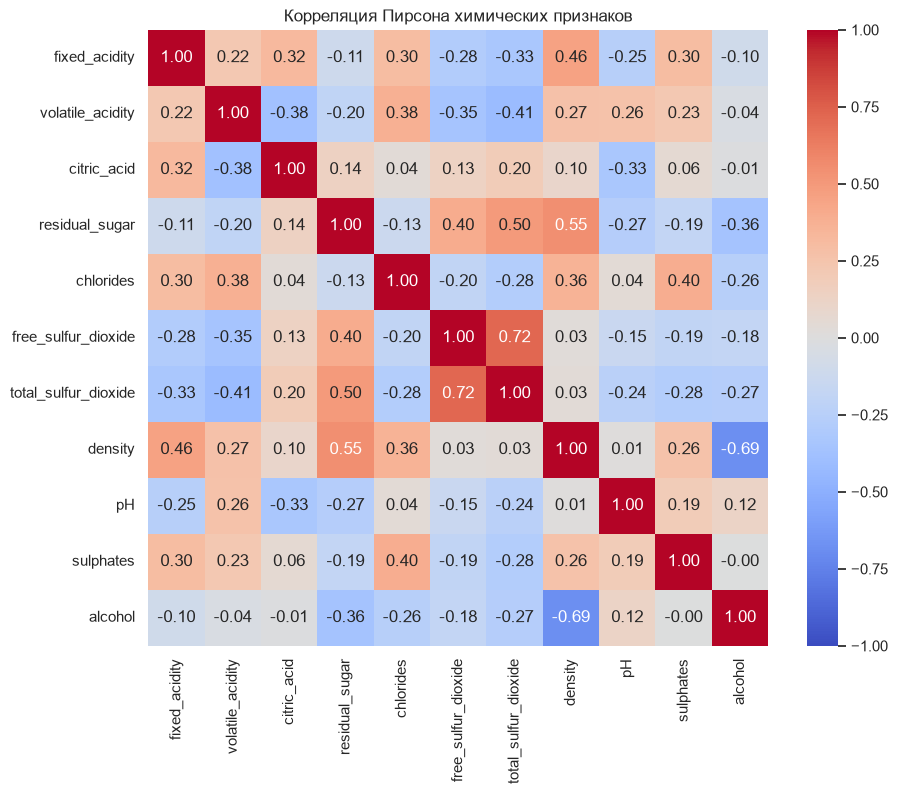

In [9]:
float_columns = [col for col in data.columns if data[col].dtype == float]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data[float_columns].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Корреляция Пирсона химических признаков')
plt.show()

Сильнее всего коррелируют `free_sulfur_dioxide` и `total_sulfur_dioxide` (0.72), `density` и `alcohol` (-0.69), `density` и `residual_sugar` (0.55). Остальные связи слабые или умеренные.

А также анализ значений асимметрии в преддверии преобразований.

In [10]:
skew_columns = data[float_columns].skew().sort_values(ascending=False)
skew_columns

chlorides               5.399828
sulphates               1.797270
fixed_acidity           1.723290
volatile_acidity        1.495097
residual_sugar          1.435404
free_sulfur_dioxide     1.220066
alcohol                 0.565718
density                 0.503602
citric_acid             0.471731
pH                      0.386839
total_sulfur_dioxide   -0.001177
dtype: float64

In [11]:
skewed_features = skew_columns.index[skew_columns > 0.75]
print('Неположительных значений в скошенных признаках:', (data[skewed_features] <= 0).sum().sum())
pd.DataFrame({'до': skew_columns[skewed_features],
              'log1p': np.log1p(data[skewed_features]).skew(),
              'log': np.log(data[skewed_features]).skew()})

Неположительных значений в скошенных признаках: 0


,до,log1p,log
chlorides,5.399828,4.484421,0.876472
sulphates,1.797270,1.098588,0.404992
fixed_acidity,1.723290,0.976702,0.889137
volatile_acidity,1.495097,1.126873,0.327799
residual_sugar,1.435404,0.414917,0.240692
free_sulfur_dioxide,1.220066,-0.721434,-0.834197


У 6 признаков асимметрия больше 0.75, их логарифмируем. Все значения этих признаков положительные, поэтому используем `np.log`. По таблице видно, что `np.log1p` уменьшает асимметрию хуже, особенно у `chlorides` (4.48 против 0.88), так как для маленьких x значение log(1 + x) почти равно x.

После логарифмирования все признаки стандартизуем с помощью `StandardScaler`. K-средние и агломеративная кластеризация используют евклидово расстояние, и без масштабирования признаки с большими значениями, например `total_sulfur_dioxide`, влияли бы на результат сильнее остальных.

In [12]:
data[skewed_features] = np.log(data[skewed_features])

scaler = StandardScaler()
data[float_columns] = scaler.fit_transform(data[float_columns])

data[float_columns].agg(['mean', 'std', 'skew']).round(2)

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
mean,0.00,0.00,0.00,0.00,0.00,-0.00,-0.0,-0.0,0.00,-0.0,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.0,1.00,1.0,1.00
skew,0.89,0.33,0.47,0.24,0.88,-0.83,-0.0,0.5,0.39,0.4,0.57


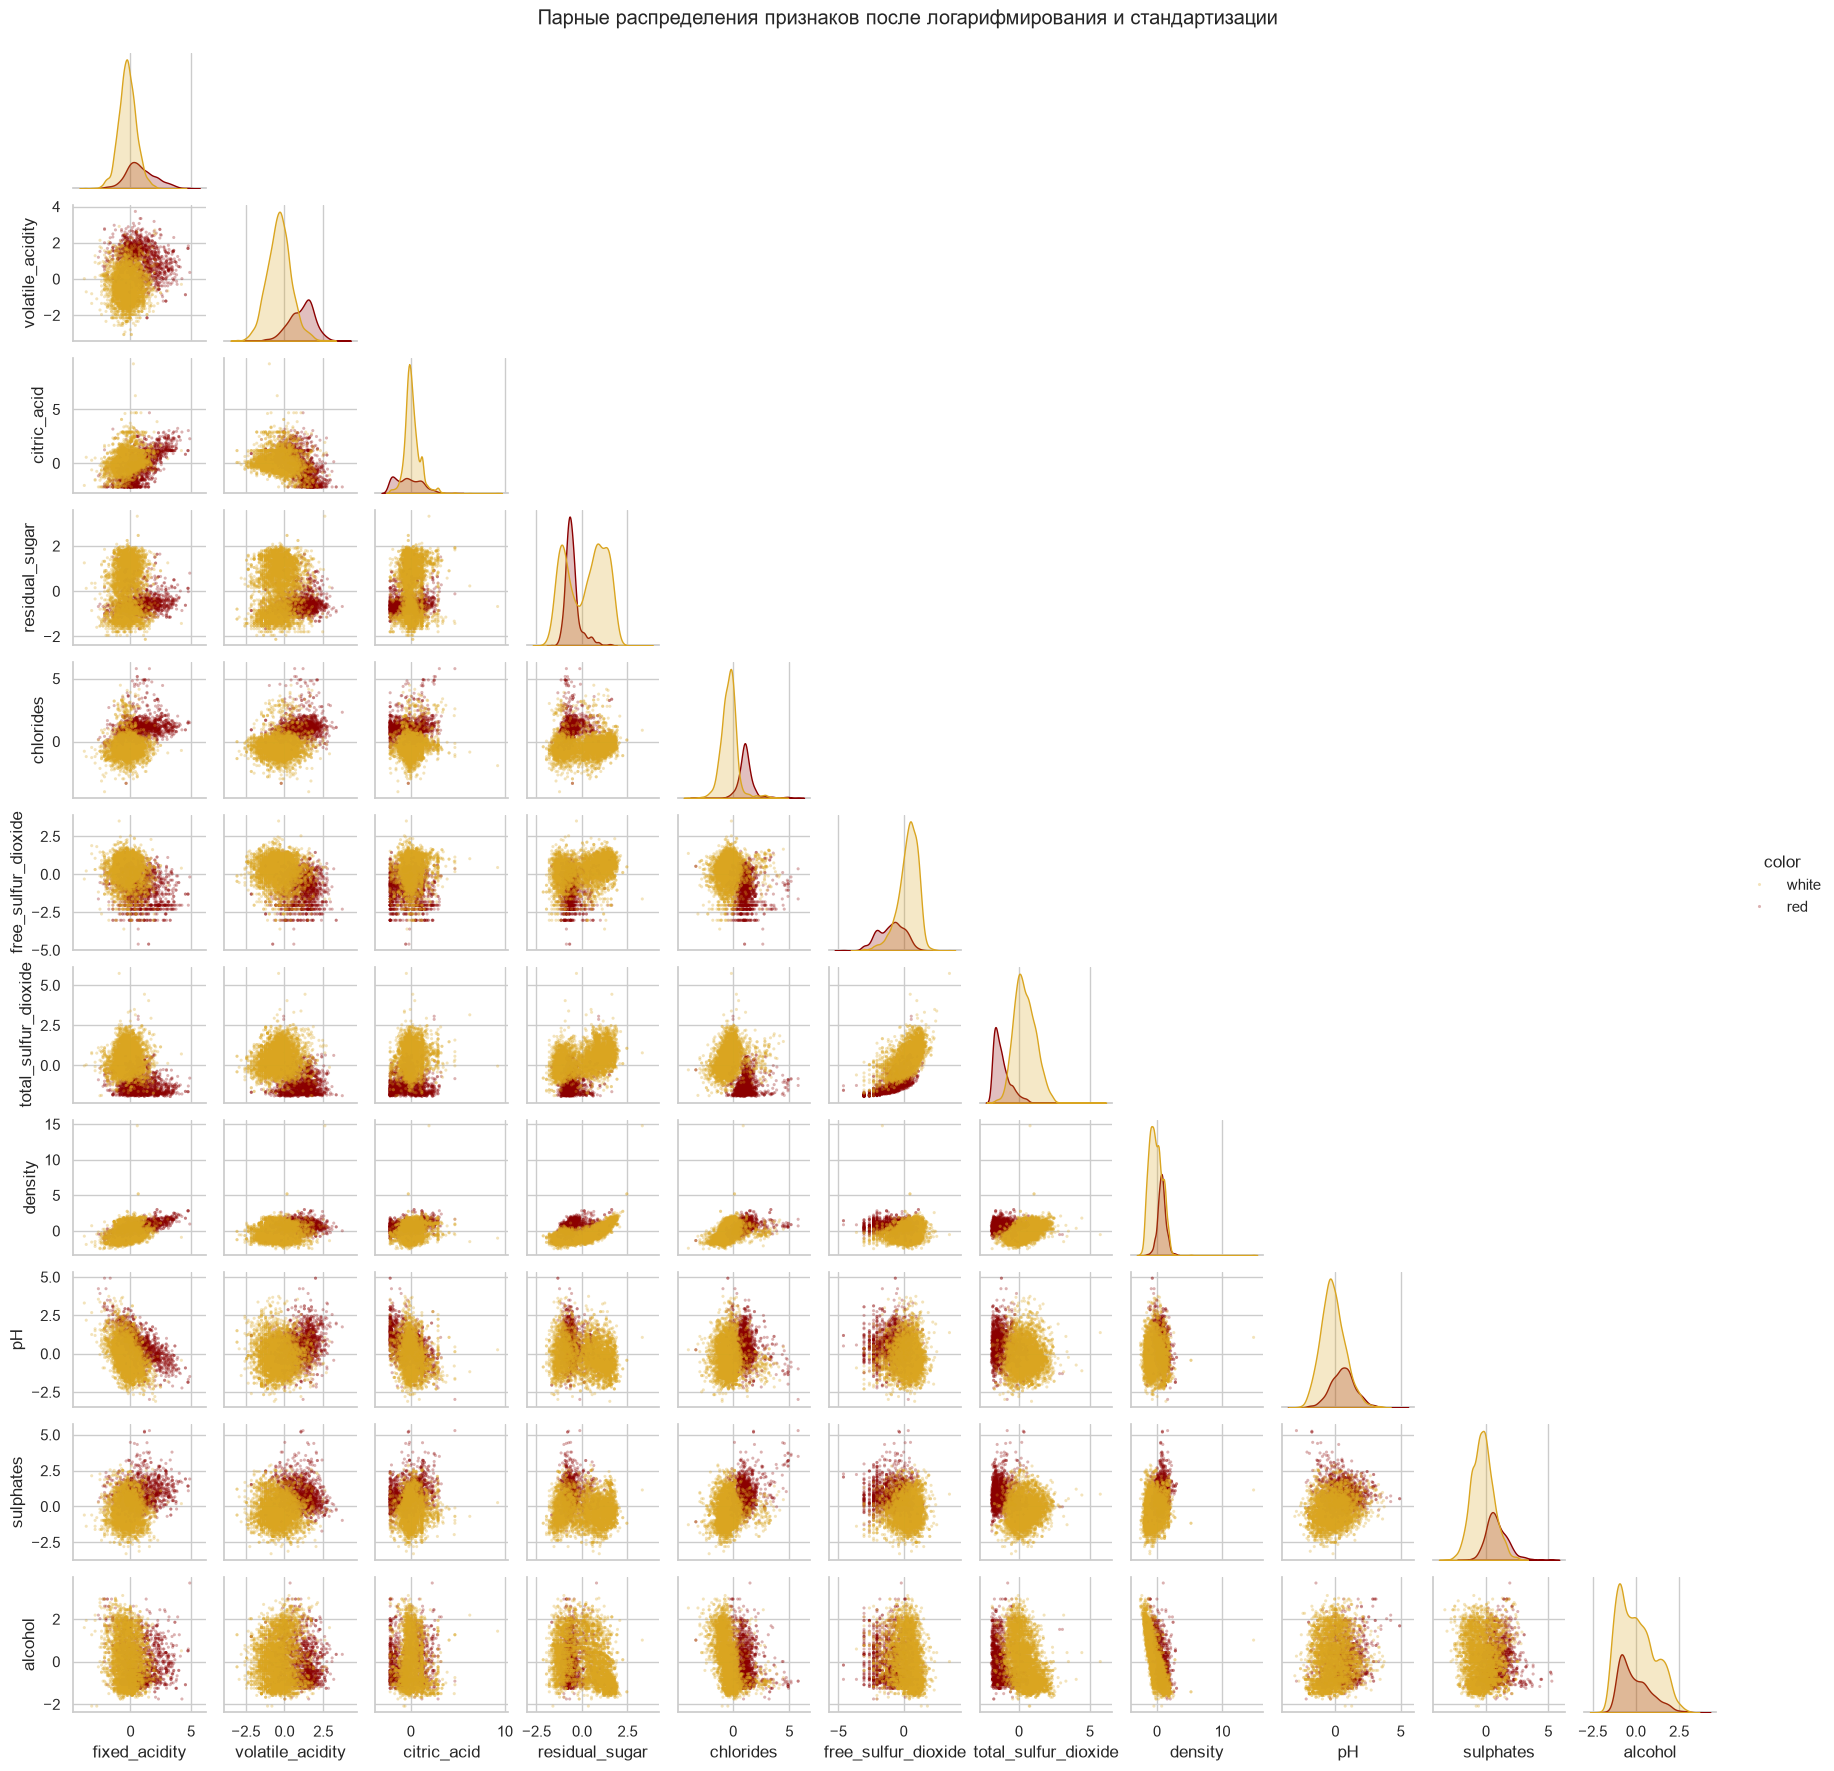

In [13]:
grid = sns.pairplot(data[float_columns + ['color']], hue='color', hue_order=['white', 'red'],
                    palette={'white': 'goldenrod', 'red': 'darkred'}, corner=True,
                    plot_kws={'s': 5, 'alpha': 0.3, 'linewidth': 0}, height=1.6)
grid.figure.suptitle('Парные распределения признаков после логарифмирования и стандартизации', y=1.01)
plt.show()

**Вывод.** После преобразований у всех признаков среднее 0 и стандартное отклонение 1, а асимметрия по модулю не больше 0.9 (у `chlorides` до преобразования было 5.4). На парных графиках видно несколько выбросов по `density` и `citric_acid`. По многим признакам, например `total_sulfur_dioxide`, `volatile_acidity` и `chlorides`, красные и белые вина хорошо разделяются, поэтому можно ожидать, что кластеризация выделит цвет вина.

## Вопрос 3

* Постройте модель кластеризации методом K-средних с двумя кластерами.
* Проанализируйте кластеры по цвету вина.

In [14]:
X = data[float_columns]

km = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
data['kmeans'] = km.fit_predict(X)

pd.crosstab(data['color'], data['kmeans'], margins=True)

kmeans,0,1,All
color,,,
red,20,1579,1599
white,4797,101,4898
All,4817,1680,6497


**Вывод.** Кластеры почти совпадают с цветом вина. В кластере 0 находятся 4797 белых и 20 красных вин, в кластере 1 - 1579 красных и 101 белое. В кластер другого цвета попало 121 вино из 6497 (около 1.9 %). Цвет в модель не передавался, значит химический состав красных и белых вин сильно отличается.

## Вопрос 4

* Теперь постройте модели K-Means с количеством кластеров от 1 до 20.
* Для каждой модели запишите количество кластеров и значение инерции.
* Постройте график зависимости количества кластеров от инерции. Можно ли выделить какое-то идеальное количество кластеров?

In [15]:
inertia = pd.Series(name='inertia', dtype=float)
for n in range(1, 21):
    inertia.loc[n] = KMeans(n_clusters=n, n_init=10, random_state=RANDOM_STATE).fit(X).inertia_
inertia.index.name = 'clusters'
inertia.to_frame()

,inertia
clusters,
1,71467.000000
2,55053.010301
3,44577.465022
4,40391.197437
5,37705.357338
6,35916.288884
7,34544.855232
8,33363.278749
9,32267.947986


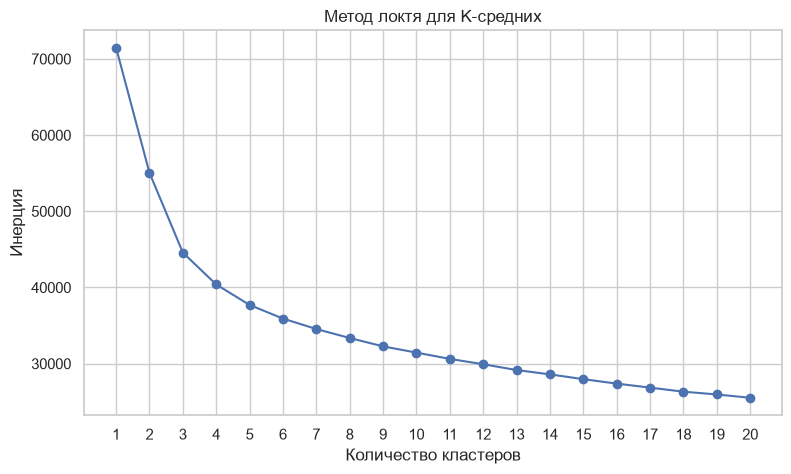

In [16]:
ax = inertia.plot(marker='o', figsize=(9, 5))
ax.set(xlabel='Количество кластеров', ylabel='Инерция', title='Метод локтя для K-средних', xticks=range(1, 21))
plt.show()

**Вывод.** Инерция уменьшается при увеличении числа кластеров, поэтому смотрим, после какого значения она перестаёт сильно падать. Больше всего она падает при переходе от 1 к 2 кластерам (примерно на 16 400) и от 2 к 3 (примерно на 10 500), от 3 к 4 уже только примерно на 4 200, дальше график убывает плавно. Чёткого локтя нет, поэтому идеальное число кластеров однозначно выделить нельзя, наиболее подходящие варианты - 2 или 3 кластера. Два кластера соответствуют цвету вина, а по дендрограмме в вопросе 5 видно, что третий кластер отделяет сладкие белые вина от сухих.

## Вопрос 5

* Постройте модель агломеративного кластеризации с двумя кластерами.
* Сравните полученные результаты с результатами, полученными с помощью алгоритма K-средних, с точки зрения цвета вина.
* Визуализируйте дендрограмму, построенную с помощью агломеративного кластеризации. *Подсказка:* В SciPy есть модуль [`cluster.hierarchy`](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html#module-scipy.cluster.hierarchy), содержащий функции `linkage` и `dendrogram`, необходимые для построения карты связей и отображения полученной дендрограммы.

In [17]:
ag = AgglomerativeClustering(n_clusters=2, linkage='ward')
data['agglom'] = ag.fit_predict(X)

pd.crosstab(data['color'], data['agglom'], margins=True)

agglom,0,1,All
color,,,
red,27,1572,1599
white,4810,88,4898
All,4837,1660,6497


Обратите внимание, что распределение по кластерам является произвольным: номера основных кластеров для красного и белого цветов могут не совпадать с приведёнными ниже, а также могут различаться при использовании метода K-средних и агломеративного кластерирования.

In [18]:
pd.crosstab([data['color'], data['agglom']], data['kmeans'])

kmeans           0     1
color agglom            
red   0         16    11
      1          4  1568
white 0       4752    58
      1         45    43

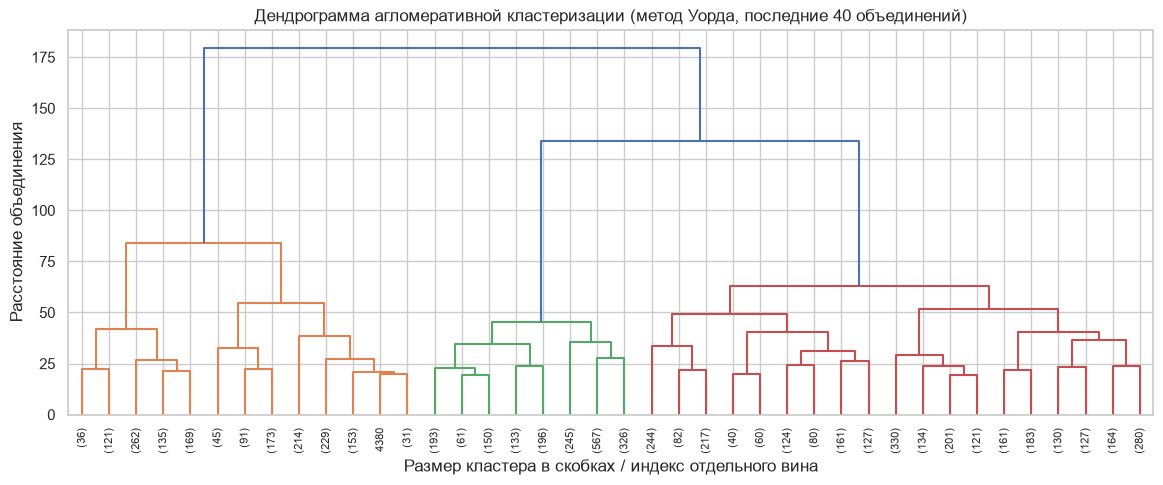

In [19]:
Z = linkage(X, method='ward')

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=40, show_leaf_counts=True, leaf_rotation=90, ax=ax)
ax.set(title='Дендрограмма агломеративной кластеризации (метод Уорда, последние 40 объединений)',
       xlabel='Размер кластера в скобках / индекс отдельного вина', ylabel='Расстояние объединения')
plt.show()

In [20]:
three_clusters = fcluster(Z, t=3, criterion='maxclust')
pd.concat([pd.crosstab(three_clusters, data['color']),
           data.groupby(three_clusters)[['residual_sugar', 'alcohol']].mean().round(2)], axis=1)

,red,white,residual_sugar,alcohol
1,1572,88,-0.55,-0.06
2,8,1863,1.14,-0.76
3,19,2947,-0.41,0.52


**Вывод.** Агломеративная кластеризация тоже разделяет вина по цвету. В «белом» кластере 4810 белых и 27 красных вин, в «красном» 1572 красных и 88 белых, всего в кластер другого цвета попало 115 вин (около 1.8 %), у K-средних было 121. Результаты двух методов почти одинаковые: метки совпадают у 6379 вин (98.2 %). Различаются они на 118 винах, которые только один из методов отнёс к кластеру другого цвета. Ещё 59 вин оба метода отнесли к кластеру другого цвета.

На дендрограмме показаны последние 40 объединений, в скобках указано число вин в кластере, без скобок - номер отдельного вина. Самое высокое объединение (расстояние около 180) соединяет красную ветвь (1660 вин) и белую (4837 вин), это и есть разбиение на 2 кластера. Следующее объединение (около 134) делит белую ветвь на две части, все остальные находятся ниже 84. По таблице для трёх кластеров видно, что эти две части - сладкие белые вина (высокий `residual_sugar` и низкий `alcohol`) и сухие. Это совпадает с большим падением инерции при переходе от 2 к 3 кластерам в вопросе 4.

## Вопрос 6

В этом вопросе мы рассмотрим кластеризацию как один из способов инженерии признаков.

* Создайте **бинарную** целевую переменную `y`, указывающую, превышает ли показатель качества значение 7 или нет.
* Создайте переменную `X_with_kmeans` на основе набора данных `data`, удалив из него столбцы «quality», «color» и «agglom». Создайте из него `X_without_kmeans`, удалив столбец «kmeans».
* Для обоих наборов данных с помощью `StratifiedShuffleSplit` с 10 разбиениями обучите 10 классификаторов Random Forest и вычислите среднее значение показателей ROC-AUC.
* Сравните средние значения показателей ROC-AUC для моделей, использующих кластеры k-средних в качестве признака, и для модели, которая их не использует.

Целевая переменная `y` равна 1 для вин с качеством выше 7, то есть с оценкой 8 или 9. Таких вин около 3 %.

In [21]:
y = (data['quality'] > 7).astype(int)
X_with_kmeans = data.drop(columns=['quality', 'color', 'agglom'])
X_without_kmeans = X_with_kmeans.drop(columns='kmeans')

print(y.value_counts(normalize=True).round(4))
print(X_with_kmeans.shape, X_without_kmeans.shape)

quality
0    0.9695
1    0.0305
Name: proportion, dtype: float64
(6497, 12) (6497, 11)


In [22]:
sss = StratifiedShuffleSplit(n_splits=10, test_size=0.3, random_state=RANDOM_STATE)


def roc_auc_scores(estimator, X, y):
    scores = []
    for train_idx, test_idx in sss.split(X, y):
        estimator.fit(X.iloc[train_idx], y.iloc[train_idx])
        scores.append(roc_auc_score(y.iloc[test_idx], estimator.predict_proba(X.iloc[test_idx])[:, 1]))
    return scores


rf = RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)
rf_scores = pd.DataFrame({'без kmeans': roc_auc_scores(rf, X_without_kmeans, y),
                          'с kmeans': roc_auc_scores(rf, X_with_kmeans, y)})
rf_scores.index.name = 'split'
rf_scores.round(4)

,без kmeans,с kmeans
split,,
0,0.8935,0.8913
1,0.8638,0.8885
2,0.8684,0.8724
3,0.8955,0.9100
4,0.8126,0.8448
5,0.9066,0.9106
6,0.9070,0.9018
7,0.8864,0.8945
8,0.8986,0.8771


In [23]:
rf_difference = rf_scores['с kmeans'] - rf_scores['без kmeans']
print(rf_scores.agg(['mean', 'std']).round(4))
print('Разность по разбиениям: mean = {:.4f}, std = {:.4f}'.format(rf_difference.mean(), rf_difference.std()))
print('Разбиений, где модель с kmeans лучше:', (rf_difference > 0).sum(), 'из', len(rf_difference))

      без kmeans  с kmeans
mean      0.8789    0.8809
std       0.0292    0.0295
Разность по разбиениям: mean = 0.0020, std = 0.0209
Разбиений, где модель с kmeans лучше: 6 из 10


**Вывод.** Средний ROC-AUC без признака `kmeans` равен 0.8789, с ним 0.8809. Разница 0.002 очень маленькая: стандартное отклонение разностей по разбиениям 0.021, а модель с `kmeans` оказалась лучше только в 6 из 10 разбиений. Значит, кластеры K-средних почти не улучшают случайный лес. Метка из двух кластеров почти повторяет цвет вина и не даёт новой информации о высоком качестве, а случайный лес и так находит нелинейные зависимости в исходных признаках.

Давайте теперь выясним, влияет ли количество кластеров на это улучшение.

* Создайте базовый обучающий набор из `data`, ограничив его столбцами с числами с плавающей запятой.
* Для $n = 1, \ldots, 20$ выполните обучение алгоритма k-средних с $n$ кластерами. Примените к данным кодирование «one-hot» и добавьте их в **базовый** обучающий набор. Не добавляйте их к результатам предыдущей итерации.
* Обучите 10 моделей **логистической регрессии** и вычислите среднее значение показателя ROC-AUC.
* Постройте график средних значений показателя ROC-AUC.

В базовый набор входят 11 химических признаков после масштабирования. Для каждого $n$ и каждого разбиения K-средние обучаются на обучающей части, для тестовой части номера кластеров получаем через `predict`. Номера кластеров кодируются one-hot и добавляются к базовому набору. Разбиения те же, что и для случайного леса. При $n = 1$ добавляется один постоянный столбец, поэтому эта модель соответствует модели без кластеров.

In [24]:
X_base = data[float_columns]


def roc_auc_scores_with_clusters(n_clusters):
    scores = []
    for train_idx, test_idx in sss.split(X_base, y):
        X_train, X_test = X_base.iloc[train_idx], X_base.iloc[test_idx]
        cluster_model = KMeans(n_clusters=n_clusters, n_init=10, random_state=RANDOM_STATE).fit(X_train)
        X_train = np.hstack([X_train, np.eye(n_clusters)[cluster_model.labels_]])
        X_test = np.hstack([X_test, np.eye(n_clusters)[cluster_model.predict(X_test)]])
        lr = LogisticRegression(max_iter=1000).fit(X_train, y.iloc[train_idx])
        scores.append(roc_auc_score(y.iloc[test_idx], lr.predict_proba(X_test)[:, 1]))
    return scores


roc_auc_by_clusters = pd.DataFrame({n: roc_auc_scores_with_clusters(n) for n in range(1, 21)}).agg(['mean', 'std']).T
roc_auc_by_clusters.index.name = 'clusters'
roc_auc_by_clusters.round(4)

,mean,std
clusters,,
1,0.7920,0.0216
2,0.7917,0.0219
3,0.7938,0.0230
4,0.7936,0.0222
5,0.7902,0.0210
6,0.7906,0.0217
7,0.7949,0.0208
8,0.7957,0.0203
9,0.8072,0.0242


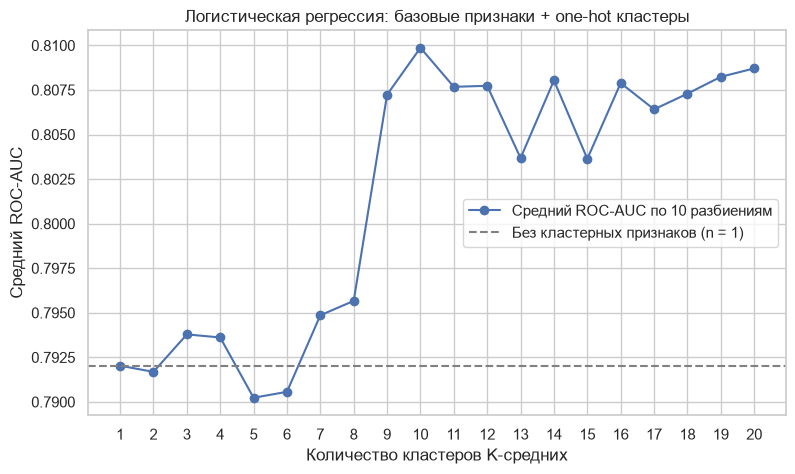

In [25]:
ax = roc_auc_by_clusters['mean'].plot(marker='o', figsize=(9, 5), label='Средний ROC-AUC по 10 разбиениям')
ax.axhline(roc_auc_by_clusters.loc[1, 'mean'], color='grey', linestyle='--', label='Без кластерных признаков (n = 1)')
ax.set(xlabel='Количество кластеров K-средних', ylabel='Средний ROC-AUC',
       title='Логистическая регрессия: базовые признаки + one-hot кластеры', xticks=range(1, 21))
ax.legend()
plt.show()

**Вывод.** При $n$ от 1 до 8 средний ROC-AUC почти не меняется (0.790-0.796, при $n = 1$ он равен 0.7920). Начиная с $n = 9$ он становится выше, 0.804-0.810, лучший результат 0.8099 при $n = 10$, то есть прирост около 0.015-0.018. Для логистической регрессии кластеры полезнее, чем для случайного леса, потому что one-hot признаки кластеров добавляют в линейную модель нелинейность. При этом разница между соседними значениями $n$ после 9 маленькая по сравнению со стандартным отклонением (около 0.02), поэтому можно сказать, что большое число кластеров немного улучшает модель, но одно лучшее значение $n$ выделить нельзя. Случайный лес всё равно работает лучше (0.88 против 0.81).